EXPERIMENT 1 - synthetic validation
  Blobs     k-means ARI =  1.000   spectral ARI =  0.990
  Circles   k-means ARI = -0.002   spectral ARI =  1.000
  Moons     k-means ARI =  0.239   spectral ARI =  1.000


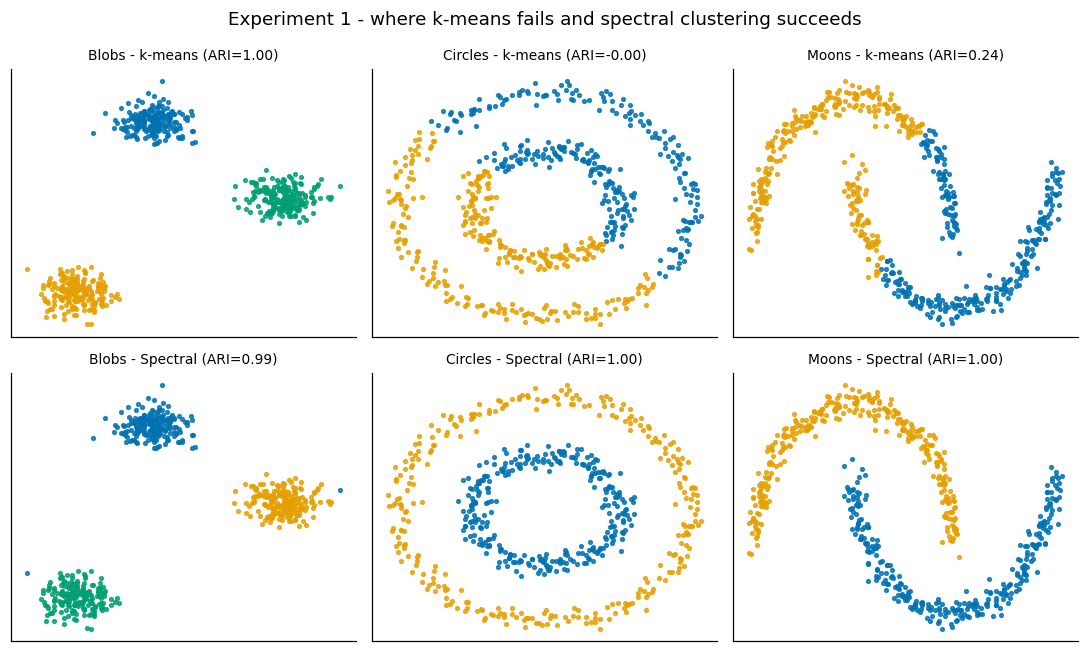


EXPERIMENT 3 - three Laplacians (two circles, noise 0.08, r = 0.3)
  sigma=0.08:  unnorm=0.980  sym=0.987  rw=0.980
  sigma=0.1:  unnorm=0.178  sym=0.980  rw=0.980


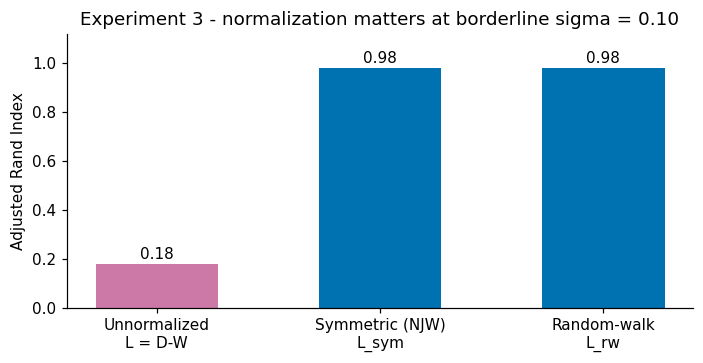


EXPERIMENT 4 - bandwidth sensitivity (r = 0.4, L_sym)
  sigma=0.05   ARI =  0.987
  sigma=0.1    ARI =  0.980
  sigma=0.15   ARI = -0.001
  sigma=0.25   ARI = -0.002
  sigma=0.5    ARI = -0.002
  sigma=1.0    ARI = -0.002


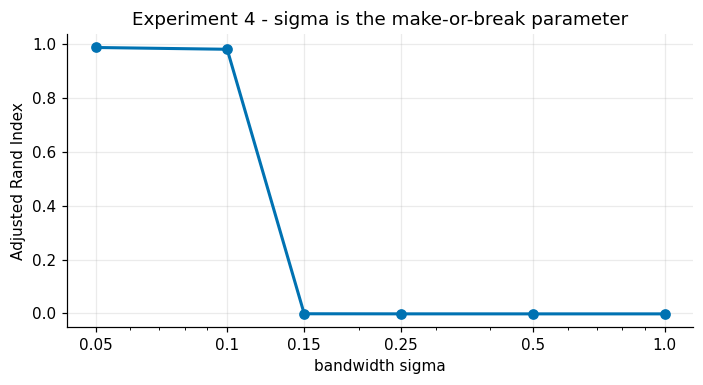


EXPERIMENT 2 & 5 - real image and runtime
  n=  2610   graph= 0.23s   eigensolve=  1.01s
  n=  7296   graph= 0.31s   eigensolve=  8.12s
  n= 14204   graph= 0.82s   eigensolve= 15.31s
    W nonzeros = 1,094,896  (0.54% dense)


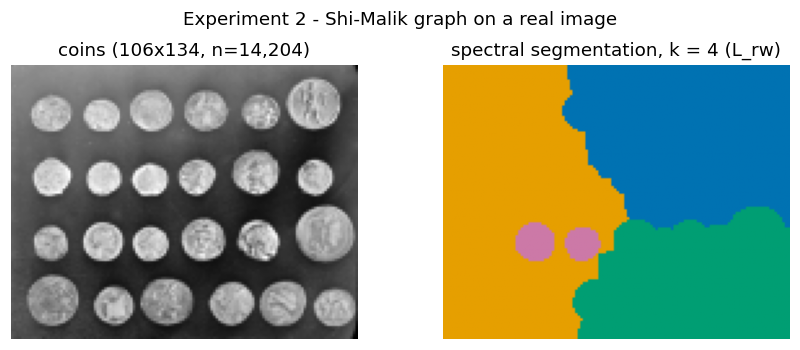

  n= 29184   graph= 0.90s   eigensolve= 17.47s
  slopes:  graph ~ n^0.63    eigensolve ~ n^1.21


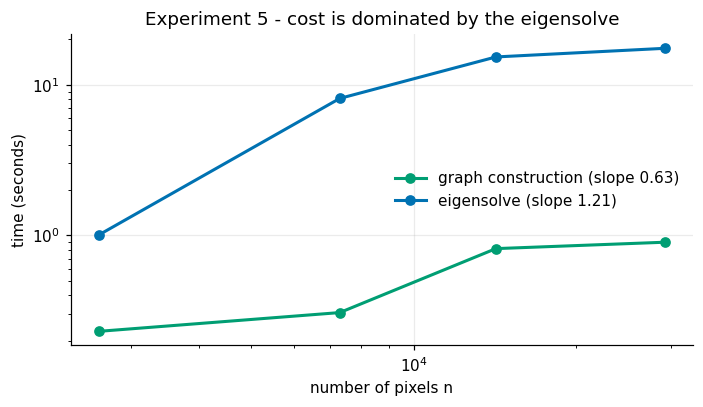


EXPERIMENT 6 - noise robustness (kNN graph)
  noise=0.02   k-means=-0.002   spectral= 1.000


/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


  noise=0.05   k-means=-0.002   spectral= 1.000
  noise=0.08   k-means=-0.002   spectral= 0.146
  noise=0.11   k-means=-0.002   spectral=-0.001
  noise=0.14   k-means=-0.001   spectral= 0.002

Done.


In [1]:
import numpy as np, time, matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_circles, make_moons
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import adjusted_rand_score as ari
from sklearn.neighbors import radius_neighbors_graph
from scipy.sparse import csr_matrix, diags, eye
from scipy.sparse.linalg import eigsh
from skimage import data
from skimage.transform import rescale

RS = 42
C = ['#0072B2', '#E69F00', '#009E73', '#CC79A7']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def graph(X, sigma, r):
    A = radius_neighbors_graph(X, r, mode='distance', include_self=False)
    A.data = np.exp(-A.data**2 / (2*sigma**2))
    return A.maximum(A.T)

def spectral(X, k, sigma, r, kind='rw'):
    W = graph(X, sigma, r)
    d = np.asarray(W.sum(1)).ravel(); d[d == 0] = 1e-12
    if kind == 'unnorm':
        _, V = eigsh(diags(d) - W, k=k, sigma=0, which='LM'); U = V
    elif kind == 'sym':
        Dm = diags(1/np.sqrt(d))
        _, V = eigsh(eye(W.shape[0]) - Dm @ W @ Dm, k=k, sigma=0, which='LM')
        U = V / np.linalg.norm(V, axis=1, keepdims=True).clip(1e-12)
    else:
        _, V = eigsh(diags(d) - W, k=k, M=diags(d), sigma=0, which='LM'); U = V
    return KMeans(k, n_init=10, random_state=RS).fit_predict(U)

# ---------- EXPERIMENT 1: synthetic validation ----------
print('EXPERIMENT 1 - synthetic validation')
sets = {'Blobs': make_blobs(n_samples=600, centers=3, cluster_std=1.0, random_state=RS),
        'Circles': make_circles(n_samples=600, factor=.5, noise=.05, random_state=RS),
        'Moons': make_moons(n_samples=600, noise=.05, random_state=RS)}
fig, ax = plt.subplots(2, 3, figsize=(10, 6))
for j, (name, (X, y)) in enumerate(sets.items()):
    k = len(set(y))
    km = KMeans(k, n_init=10, random_state=RS).fit_predict(X)
    sc = spectral(X, k, .3, 1.0) if name == 'Blobs' else spectral(X, k, .08, .3)
    print(f'  {name:8s}  k-means ARI = {ari(y,km):6.3f}   spectral ARI = {ari(y,sc):6.3f}')
    for i, (lab, t) in enumerate([(km, 'k-means'), (sc, 'Spectral')]):
        for c in range(k):
            ax[i, j].scatter(*X[lab == c].T, s=6, color=C[c], alpha=.8)
        ax[i, j].set_title(f'{name} - {t} (ARI={ari(y,lab):.2f})', fontsize=9)
        ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
fig.suptitle('Experiment 1 - where k-means fails and spectral clustering succeeds')
fig.tight_layout(); plt.show()

# ---------- EXPERIMENT 3: three Laplacians ----------
print('\nEXPERIMENT 3 - three Laplacians (two circles, noise 0.08, r = 0.3)')
X, y = make_circles(n_samples=600, factor=.5, noise=.08, random_state=RS)
res = {}
for s in [0.08, 0.10]:
    res[s] = {k: ari(y, spectral(X, 2, s, .3, k)) for k in ['unnorm', 'sym', 'rw']}
    print(f'  sigma={s}:  unnorm={res[s]["unnorm"]:.3f}  sym={res[s]["sym"]:.3f}  rw={res[s]["rw"]:.3f}')
v = [res[0.10][k] for k in ['unnorm', 'sym', 'rw']]
fig, a = plt.subplots(figsize=(6.5, 3.4))
b = a.bar(['Unnormalized\nL = D-W', 'Symmetric (NJW)\nL_sym', 'Random-walk\nL_rw'], v,
          color=[C[3], C[0], C[0]], width=.55)
for rct, val in zip(b, v):
    a.text(rct.get_x()+rct.get_width()/2, val+.02, f'{val:.2f}', ha='center')
a.set_ylabel('Adjusted Rand Index'); a.set_ylim(0, 1.12)
a.set_title('Experiment 3 - normalization matters at borderline sigma = 0.10')
fig.tight_layout(); plt.show()

# ---------- EXPERIMENT 4: bandwidth sensitivity ----------
print('\nEXPERIMENT 4 - bandwidth sensitivity (r = 0.4, L_sym)')
sig = [.05, .1, .15, .25, .5, 1.0]; scores = []
for s in sig:
    a_ = ari(y, spectral(X, 2, s, .4, 'sym')); scores.append(a_)
    print(f'  sigma={s:<5}  ARI = {a_:6.3f}')
fig, a = plt.subplots(figsize=(6.5, 3.6))
a.plot(sig, scores, '-o', color=C[0], lw=2); a.set_xscale('log')
a.set_xticks(sig); a.set_xticklabels(map(str, sig)); a.grid(alpha=.25)
a.set_xlabel('bandwidth sigma'); a.set_ylabel('Adjusted Rand Index')
a.set_title('Experiment 4 - sigma is the make-or-break parameter')
fig.tight_layout(); plt.show()

# ---------- EXPERIMENTS 2 & 5: real image and cost ----------
print('\nEXPERIMENT 2 & 5 - real image and runtime')
img0 = data.coins()

def build(im, r=5., sI=.1, sX=4.):
    h, w = im.shape; n = h*w
    xy = np.dstack(np.meshgrid(np.arange(h), np.arange(w), indexing='ij')).reshape(-1, 2).astype(float)
    f = im.reshape(-1, 1)
    t0 = time.time()
    A = radius_neighbors_graph(xy, r, mode='distance', include_self=False).tocoo()
    wd = np.exp(-((f[A.row,0]-f[A.col,0])**2)/(2*sI**2)) * np.exp(-(A.data**2)/(2*sX**2))
    W = csr_matrix((wd, (A.row, A.col)), shape=(n, n)); W = W.maximum(W.T)
    tg = time.time()-t0
    d = np.asarray(W.sum(1)).ravel(); d[d == 0] = 1e-12
    return W, d, tg, h, w, n

build(rescale(img0, .15, anti_aliasing=True))   # warm-up, keeps the timings honest
ns, tgs, tes = [], [], []
for sc_ in [.15, .25, .35, .5]:
    im = rescale(img0, sc_, anti_aliasing=True)
    W, d, tg, h, w, n = build(im)
    t0 = time.time(); _, V = eigsh(diags(d)-W, k=4, M=diags(d), sigma=0, which='LM'); te = time.time()-t0
    ns.append(n); tgs.append(tg); tes.append(te)
    print(f'  n={n:6d}   graph={tg:5.2f}s   eigensolve={te:6.2f}s')
    if abs(sc_-.35) < 1e-9:
        lab = KMeans(4, n_init=10, random_state=RS).fit_predict(V).reshape(h, w)
        print(f'    W nonzeros = {W.nnz:,}  ({100*W.nnz/n**2:.2f}% dense)')
        f2, a2 = plt.subplots(1, 2, figsize=(8, 3.2))
        a2[0].imshow(im, cmap='gray'); a2[0].set_title(f'coins ({h}x{w}, n={n:,})')
        a2[1].imshow(lab, cmap=plt.matplotlib.colors.ListedColormap(C))
        a2[1].set_title('spectral segmentation, k = 4 (L_rw)')
        for x in a2: x.axis('off')
        f2.suptitle('Experiment 2 - Shi-Malik graph on a real image')
        f2.tight_layout(); plt.show()

sg = np.polyfit(np.log(ns), np.log(tgs), 1)[0]; se = np.polyfit(np.log(ns), np.log(tes), 1)[0]
print(f'  slopes:  graph ~ n^{sg:.2f}    eigensolve ~ n^{se:.2f}')
fig, a = plt.subplots(figsize=(6.5, 3.8))
a.loglog(ns, tgs, '-o', color=C[2], lw=2, label=f'graph construction (slope {sg:.2f})')
a.loglog(ns, tes, '-o', color=C[0], lw=2, label=f'eigensolve (slope {se:.2f})')
a.set_xlabel('number of pixels n'); a.set_ylabel('time (seconds)')
a.grid(alpha=.25); a.legend(frameon=False)
a.set_title('Experiment 5 - cost is dominated by the eigensolve')
fig.tight_layout(); plt.show()

# ---------- EXPERIMENT 6: noise robustness ----------
print('\nEXPERIMENT 6 - noise robustness (kNN graph)')
for nz in [.02, .05, .08, .11, .14]:
    Xn, yn = make_circles(n_samples=600, factor=.5, noise=nz, random_state=RS)
    km = KMeans(2, n_init=10, random_state=RS).fit_predict(Xn)
    sc = SpectralClustering(2, affinity='nearest_neighbors', n_neighbors=10,
                            random_state=RS).fit_predict(Xn)
    print(f'  noise={nz:<5}  k-means={ari(yn,km):6.3f}   spectral={ari(yn,sc):6.3f}')
print('\nDone.')